# Storyline 3: How do cost differences relate to output and task mix?

**Core question: Does lower cost per FTE accompany lower output per FTE? Does higher cost accompany a larger complex-request share?**

FY2008–FY2025 | Top ten agencies by requests received, with an all-agency cross-sectional comparison

Sequence: cost and output → complex-request share → track-specific processing time → findings. Measures are assessed separately, without an overall efficiency score.

## 1. Sample and measurement

The fixed top ten are ranked by observed cumulative requests received in FY2008–FY2025: DHS, DOJ, DoD, HHS, VA, NARA, SSA, USDA, DOL, and DOS. Agency-overall rows are used without adding components again. Missing years are not filled with zeros; annual changes require consecutive years.

Personnel uses the original type 22 `TotalFullTimeStaffQuantity`. Cost uses the original type 23 `ProcessingCostAmount`. Neither is reconstructed. Observations are retained and flagged when the full-time plus equivalent-FTE sum differs from total FTE by more than 0.02, or processing plus litigation costs differ from total cost by more than USD 1. Blank, nonnumeric, and negative values are missing; zero denominators produce missing ratios.

Costs are expressed in FY2025 prices. Local BLS CPI-U monthly values are averaged over the federal fiscal year (previous October through current September): real cost = nominal cost × CPI_FY2025 / CPI_FYt. Source: [BLS U.S. city average, all-items CPI-U](https://www.bls.gov/regions/northeast/data/consumerpriceindex_us_table.htm), locally collected on November 15, 2026. CPI adjusts purchasing power; it is not a FOIA-specific input-price index.

This notebook runs independently from a fresh Python kernel. All reported relationships are descriptive.

Type 14 processing times recorded as `<1` are displayed as one day following the local EDA convention. Other nonnumeric and negative values remain missing. Personnel and cost may cover appeals and other work; type 01 completions include administrative closures. These measures may therefore cover different tasks.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'font.sans-serif': ['DejaVu Sans'], 'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 200)
data_directories = [Path('.'), Path('fa26/storyline'), Path('storyline')]
ROOT = next((p for p in data_directories if (p / 'component_master_no_03_06_11.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Keep the two CSV files beside the notebooks, or run from the repository root.')
SOURCE = ROOT / 'component_master_no_03_06_11.csv'
CPI = ROOT / 'cpi_u_bls_monthly_2007_2025.csv'
raw = pd.read_csv(SOURCE, dtype=str, keep_default_na=False)
fields = {'fte': '22_Personnel__TotalFullTimeStaffQuantity', 'fulltime': '22_Personnel__FullTimeEmployeeQuantity', 'equivalent': '22_Personnel__EquivalentFullTimeEmployeeQuantity', 'cost': '23_Costs__ProcessingCostAmount', 'total': '23_Costs__TotalCostAmount', 'litigation': '23_Costs__LitigationCostAmount', 'received': '01_Requests__ProcessingStatisticsReceivedQuantity', 'processed': '01_Requests__ProcessingStatisticsProcessedQuantity', 'backlog': '26_Backlog__BackloggedRequestQuantity', 'pending': '01_Requests__ProcessingStatisticsPendingAtEndQuantity', 'backlog_current_comparison': '30_ComparisonsRequestsBacklogged__BacklogCurrentYearQuantity', 'backlog_previous_comparison': '30_ComparisonsRequestsBacklogged__BacklogLastYearQuantity'}
labels = {'fte': 'Total FTE', 'fulltime': 'Full-time employees', 'equivalent': 'Equivalent FTE', 'cost': 'Nominal processing cost', 'total': 'Nominal total cost', 'litigation': 'Nominal litigation cost', 'received': 'Requests received', 'processed': 'Requests processed', 'backlog': 'Request backlog', 'pending': 'Pending requests', 'backlog_current_comparison': 'Current-year backlog in same report', 'backlog_previous_comparison': 'Prior-year backlog in same report', 'agency': 'Agency', 'year': 'Fiscal year'}
a = raw[raw['Row Type'].eq('agency_overall') & ~raw['Exclude From Component Sum'].str.strip().str.lower().eq('yes')].copy()
a['agency'] = a['Agency Abbreviation'].str.strip()
a['year'] = pd.to_numeric(a['Fiscal Year'], errors='raise').astype(int)
assert not a.duplicated(['agency', 'year']).any()
for short, col in fields.items():
    v = pd.to_numeric(a[col], errors='coerce')
    a[short] = v.mask(v.lt(0))
a = a.sort_values(['agency', 'year']).reset_index(drop=True)
ranking = a.groupby('agency').received.sum(min_count=1).sort_values(ascending=False)
TOP = ranking.head(10).index.tolist()
names = {'DHS': 'Homeland Security', 'DOJ': 'Justice', 'DoD': 'Defense', 'HHS': 'Health and Human Services', 'VA': 'Veterans Affairs', 'NARA': 'National Archives', 'SSA': 'Social Security Administration', 'USDA': 'Agriculture', 'DOL': 'Labor', 'DOS': 'State'}
colors = {ag: plt.cm.tab10(i) for i, ag in enumerate(TOP)}

def table(frame, mapping=None, digits=3):
    display(frame.rename(columns=mapping or {}).round(digits))

def finish(fig):
    fig.tight_layout()
    plt.show()

def panel_grid():
    return plt.subplots(5, 2, figsize=(15, 19))

def style_year(ax, ag, ylabel):
    ax.set(title=ag, xlabel='Fiscal year', ylabel=ylabel)
    ax.set_xticks([2008, 2012, 2016, 2020, 2025])
display(pd.DataFrame({'Item': ['Main data file', 'SHA-256', 'Local CPI file'], 'Value': [str(SOURCE.resolve()), hashlib.sha256(SOURCE.read_bytes()).hexdigest(), str(CPI)]}))
for short, source in {'simple_days': '14_ProcessingTime__SimpleResponseTime.ResponseTimeMedianDaysValue', 'complex_days': '14_ProcessingTime__ComplexResponseTime.ResponseTimeMedianDaysValue'}.items():
    s = a[source].str.strip()
    a[short] = pd.to_numeric(s, errors='coerce').mask(s.str.fullmatch('<\\s*1'), 1)
    a[short] = a[short].mask(a[short].lt(0))
    a[short + '_lt1'] = s.str.fullmatch('<\\s*1')

def rate_text(values, direction='down'):
    s = values.dropna()
    if not len(s):
        return 'No valid pairs'
    count = int(s.lt(0).sum()) if direction == 'down' else int(s.gt(0).sum())
    return f'{count}/{len(s)}({100 * count / len(s):.1f}%)'

,Item,Value
0,Main data file,C:\Users\11065\Desktop\DS701\MUCROCK\ds-muckro...
1,SHA-256,0674f1a3d96d6c3fc6dc2269b593e132c351bee6e6fedd...
2,Local CPI file,cpi_u_bls_monthly_2007_2025.csv


In [2]:
monthly = pd.read_csv(CPI).melt('year', var_name='month', value_name='cpi')
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly['fy'] = monthly.year + monthly.month.map({m: i >= 9 for i, m in enumerate(months)}).astype(int)
cpi_rows = []
for y in range(2008, 2026):
    g = monthly[monthly.fy.eq(y)]
    assert len(g) == 12 and g.cpi.notna().all()
    cpi_rows.append([y, g.cpi.mean()])
price = pd.DataFrame(cpi_rows, columns=['year', 'cpi'])
a = a.merge(price, on='year', validate='many_to_one')
base = price.loc[price.year.eq(2025), 'cpi'].iloc[0]
for v in ['cost', 'total', 'litigation']:
    a['real_' + v] = a[v] * base / a.cpi
a['fte_gap'] = a.fte - a.fulltime - a.equivalent
a['cost_gap'] = a.total - a.cost - a.litigation
a['fte_flag'] = a.fte_gap.abs().gt(0.02)
a['cost_flag'] = a.cost_gap.abs().gt(1)
a['inventory_flag'] = a.backlog.gt(a.pending)
a['backlog_table_flag'] = (a.backlog - a.backlog_current_comparison).abs().gt(0.01)
a = a.sort_values(['agency', 'year']).reset_index(drop=True)
consecutive = a.year.sub(a.groupby('agency').year.shift()).eq(1)
for v in ['fte', 'real_cost', 'backlog', 'received', 'processed']:
    prev = a.groupby('agency')[v].shift().where(consecutive)
    a['prev_' + v] = prev
    a['g_' + v] = a[v] / prev.where(prev.gt(0)) - 1
    a['delta_' + v] = a[v] - prev
a['revision_gap'] = a.backlog_previous_comparison - a.prev_backlog
d = a[a.agency.isin(TOP)].copy()
flags = ['fte_flag', 'cost_flag', 'inventory_flag', 'backlog_table_flag']
a['previous_type30_current'] = a.groupby('agency').backlog_current_comparison.shift().where(consecutive)
a['type30_cross_gap'] = a.backlog_previous_comparison - a.previous_type30_current
a['cross_flag'] = a.type30_cross_gap.abs().gt(0.01) | a.revision_gap.abs().gt(0.01)
next_con = a.groupby('agency').year.shift(-1).sub(a.year).eq(1)
next_cross = a.groupby('agency').cross_flag.shift(-1).eq(True) & next_con
a['quality_flag'] = a[flags].any(axis=1) | a.cross_flag | next_cross
a['pair_flag'] = a.quality_flag | a.groupby('agency').quality_flag.shift().eq(True)
d = a[a.agency.isin(TOP)].copy()
for metric, numerator, denominator in [('cost_per_fte', 'real_cost', 'fte'), ('backlog_per_fte', 'backlog', 'fte'), ('received_per_fte', 'received', 'fte'), ('processed_per_fte', 'processed', 'fte'), ('cost_per_completed', 'real_cost', 'processed'), ('clearance', 'processed', 'received')]:
    d[metric] = d[numerator] / d[denominator].where(d[denominator].gt(0))
con = d.year.sub(d.groupby('agency').year.shift()).eq(1)
nxt = d.groupby('agency').year.shift(-1).sub(d.year).eq(1)
for v in ['cost_per_fte', 'backlog_per_fte', 'received_per_fte', 'processed_per_fte', 'cost_per_completed', 'simple_days', 'complex_days']:
    prev = d.groupby('agency')[v].shift().where(con)
    d['prev_' + v] = prev
    d['delta_' + v] = d[v] - prev
    d['g_' + v] = d[v] / prev.where(prev.gt(0)) - 1
for v in ['delta_backlog', 'delta_backlog_per_fte', 'delta_processed', 'delta_processed_per_fte']:
    d['next_' + v] = d.groupby('agency')[v].shift(-1).where(nxt)
coverage = d.groupby('agency').agg(First_year=('year', 'min'), Last_year=('year', 'max'), Observed_years=('year', 'size'))
coverage['Cumulative requests received'] = ranking.reindex(coverage.index)
display(coverage.reindex(TOP))
display(Markdown(f'The sample contains {len(d)} agency-year records, accounting for {100 * ranking.loc[TOP].sum() / ranking.sum():.1f}%.'))

,First_year,Last_year,Observed_years,Cumulative requests received
agency,,,,
DHS,2008,2025,18,6986129
DOJ,2008,2025,18,1547577
DoD,2008,2025,18,1121517
HHS,2008,2025,18,862678
VA,2008,2025,18,816975
NARA,2008,2025,18,528895
SSA,2008,2025,18,406106
USDA,2010,2025,16,365205
DOL,2008,2025,18,297922


The sample contains 178 agency-year records, accounting for 85.9%.

In [3]:
table(d.loc[d.fte_flag | d.cost_flag, ['agency', 'year', 'fte_gap', 'cost_gap']], {'agency': 'Agency', 'year': 'Fiscal year', 'fte_gap': 'Total FTE minus component sum', 'cost_gap': 'Total cost minus component sum'}, 2)
display(Markdown('Flagged observations are retained without automatic correction. Cost per FTE measures spending relative to personnel input; it is not average pay.'))

,Agency,Fiscal year,Total FTE minus component sum,Total cost minus component sum
459,DoD,2025,0.91,0.0


Flagged observations are retained without automatic correction. Cost per FTE measures spending relative to personnel input; it is not average pay.

In [4]:
d['quality_flag'] = d.fte_flag | d.cost_flag

## 2. Does lower cost per FTE accompany lower completions per FTE?

Combine types **23 (real processing cost), 22 (total FTE), and 01 (all completions)**. First compare agencies in the latest common fiscal year, then report within-agency correlations in levels and consecutive-year changes. Each agency uses its own available years; missing years are not imputed.

Each point represents one agency. Dashed lines show medians among valid agencies in that year. Low means below this group's median, not below an industry standard. Both ratios share FTE, which may generate mechanical correlation. Real cost per completion is also shown to help distinguish low input from high output, without assigning an overall efficiency ranking.

,Agency,Fiscal year,Real cost per FTE (USD),Completions per FTE,Real cost per completion (USD),Cost below median,Output below median,Input-data flag
297,DHS,2025,168894.11,1770.45,95.40,False,False,False
387,DOJ,2025,182873.45,266.45,686.33,False,False,False
405,DOL,2025,57289.71,135.24,423.60,True,True,False
423,DOS,2025,193231.81,120.18,1607.83,False,True,False
459,DoD,2025,68307.83,74.43,917.72,True,True,True
881,HHS,2025,149680.93,142.78,1048.32,False,True,False
1047,NARA,2025,40794.08,678.45,60.13,True,False,False
1610,SSA,2025,149693.77,449.95,332.69,False,False,False
1783,USDA,2025,78331.71,111.03,705.49,True,True,False
1922,VA,2025,83170.29,523.42,158.90,True,False,False


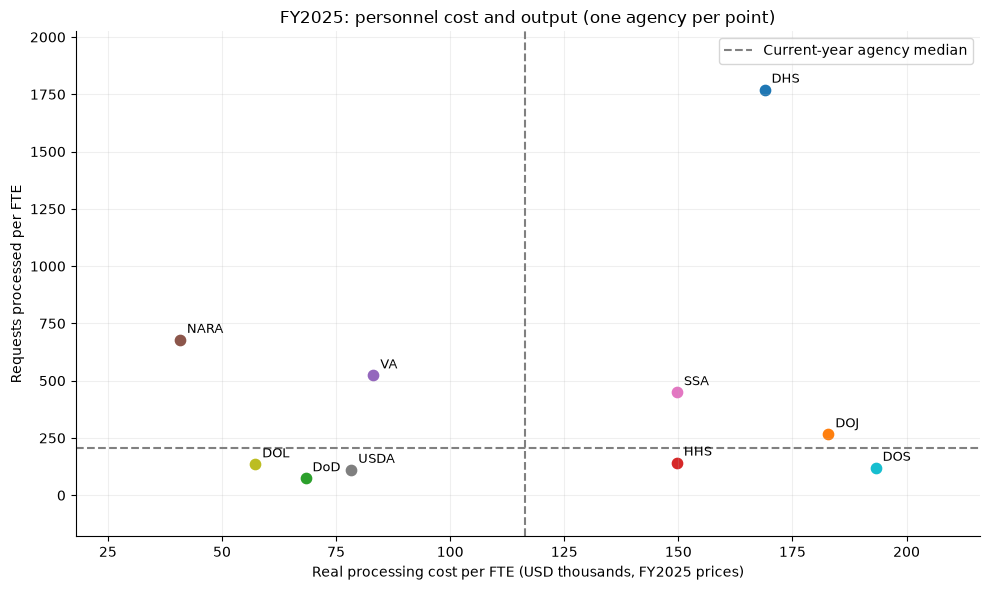

,Agency,Valid level years,Level Pearson,Consecutive-year pairs,Change Pearson
0,DHS,18,0.525,17,0.561
1,DOJ,18,0.354,17,0.041
2,DoD,18,0.655,17,0.428
3,HHS,18,0.562,17,0.126
4,VA,18,0.048,17,0.326
5,NARA,18,-0.062,17,0.202
6,SSA,18,0.494,17,0.582
7,USDA,16,0.362,15,0.285
8,DOL,18,-0.186,17,-0.041
9,DOS,18,-0.278,17,-0.053


**Interpretation:** In the latest year, across 10 comparable agencies, the indicators show positive correlation (r=0.195). Of the 5 agencies below the current-year cost median, 3 also fall below the output median (DOL, DoD, USDA); the remaining agencies are NARA, VA.

This checks whether low cost and low output coexist; it does not establish that cutting costs reduces output.

**Within each agency:**

- **DHS:** Levels: positive correlation (r=0.525); consecutive-year changes: positive correlation (r=0.561).
- **DOJ:** Levels: positive correlation (r=0.354); consecutive-year changes: positive correlation (r=0.041).
- **DoD:** Levels: positive correlation (r=0.655); consecutive-year changes: positive correlation (r=0.428).
- **HHS:** Levels: positive correlation (r=0.562); consecutive-year changes: positive correlation (r=0.126).
- **VA:** Levels: positive correlation (r=0.048); consecutive-year changes: positive correlation (r=0.326).
- **NARA:** Levels: negative correlation (r=-0.062); consecutive-year changes: positive correlation (r=0.202).
- **SSA:** Levels: positive correlation (r=0.494); consecutive-year changes: positive correlation (r=0.582).
- **USDA:** Levels: positive correlation (r=0.362); consecutive-year changes: positive correlation (r=0.285).
- **DOL:** Levels: negative correlation (r=-0.186); consecutive-year changes: negative correlation (r=-0.041).
- **DOS:** Levels: negative correlation (r=-0.278); consecutive-year changes: negative correlation (r=-0.053).

Level and change correlations may differ because long-run trends and short-run movements differ. The shared FTE denominator still requires caution.

In [5]:
def paired_corr(frame, x, y):
    q = frame[[x, y]].replace([np.inf, -np.inf], np.nan).dropna()
    r = q[x].corr(q[y]) if len(q) >= 3 and q[x].nunique() > 1 and (q[y].nunique() > 1) else np.nan
    return (len(q), r)

def corr_words(value):
    if pd.isna(value):
        return 'insufficient data or no variation to calculate correlation'
    return f"{('positive' if value > 0 else 'negative' if value < 0 else 'zero')} correlation (r={value:.3f})"
co = d.copy().sort_values(['agency', 'year'])
co_consecutive = co.year.sub(co.groupby('agency').year.shift()).eq(1)
for v in ['cost_per_fte', 'processed_per_fte']:
    previous = co.groupby('agency')[v].shift().where(co_consecutive)
    co['change_' + v] = co[v] - previous
co_latest = co[co.year.eq(co.year.max())].dropna(subset=['cost_per_fte', 'processed_per_fte']).copy()
cost_mid = co_latest.cost_per_fte.median()
output_mid = co_latest.processed_per_fte.median()
co_latest['Cost below median'] = co_latest.cost_per_fte.lt(cost_mid)
co_latest['Output below median'] = co_latest.processed_per_fte.lt(output_mid)
table(co_latest[['agency', 'year', 'cost_per_fte', 'processed_per_fte', 'cost_per_completed', 'Cost below median', 'Output below median', 'quality_flag']], {'agency': 'Agency', 'year': 'Fiscal year', 'cost_per_fte': 'Real cost per FTE (USD)', 'processed_per_fte': 'Completions per FTE', 'cost_per_completed': 'Real cost per completion (USD)', 'quality_flag': 'Input-data flag'}, 2)
fig, ax = plt.subplots(figsize=(10, 6))
for _, row in co_latest.iterrows():
    ax.scatter(row.cost_per_fte / 1000, row.processed_per_fte, color=colors[row.agency], s=55)
    ax.annotate(row.agency, (row.cost_per_fte / 1000, row.processed_per_fte), xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.axvline(cost_mid / 1000, color='gray', ls='--', label='Current-year agency median')
ax.axhline(output_mid, color='gray', ls='--')
ax.margins(0.15)
ax.set(xlabel='Real processing cost per FTE (USD thousands, FY2025 prices)', ylabel='Requests processed per FTE', title=f'FY{int(co.year.max())}: personnel cost and output (one agency per point)')
ax.legend()
finish(fig)
co_rows = []
for ag in TOP:
    q = co[co.agency.eq(ag)]
    n, r = paired_corr(q, 'cost_per_fte', 'processed_per_fte')
    nd, rd = paired_corr(q, 'change_cost_per_fte', 'change_processed_per_fte')
    co_rows.append([ag, n, r, nd, rd])
co_corr = pd.DataFrame(co_rows, columns=['Agency', 'Valid level years', 'Level Pearson', 'Consecutive-year pairs', 'Change Pearson'])
table(co_corr)
low_cost = co_latest[co_latest['Cost below median']]
low_both = low_cost[low_cost['Output below median']]
counter = low_cost[~low_cost['Output below median']]
latest_n, latest_r = paired_corr(co_latest, 'cost_per_fte', 'processed_per_fte')
co_notes = []
for _, row in co_corr.iterrows():
    co_notes.append(f"- **{row['Agency']}:** Levels: {corr_words(row['Level Pearson'])}; consecutive-year changes: {corr_words(row['Change Pearson'])}.")
display(Markdown(f"**Interpretation:** In the latest year, across {latest_n} comparable agencies, the indicators show {corr_words(latest_r)}. Of the {len(low_cost)} agencies below the current-year cost median, {len(low_both)} also fall below the output median ({', '.join(low_both.agency) or 'none'}); the remaining agencies are {', '.join(counter.agency) or 'none'}.\n\nThis checks whether low cost and low output coexist; it does not establish that cutting costs reduces output.\n\n**Within each agency:**\n\n" + '\n'.join(co_notes) + '\n\nLevel and change correlations may differ because long-run trends and short-run movements differ. The shared FTE denominator still requires caution.'))

### 2.1 All agencies: cost and completions per FTE

Use the same latest fiscal year as the top-ten chart, expanded to all agency-overall records. Each point is an agency; gray represents other agencies and colors highlight the top ten. FTE must be positive and both cost and completions valid. Zero cost or completions are retained; missing values are not filled with zeros.

The panels use the same sample on linear and compressed scales. The compressed panel uses logarithmic scaling above 1 and a linear region near zero, retaining zero values. Dashed lines are medians for all plotted agencies. Correlations use original numerical values rather than transformed coordinates.

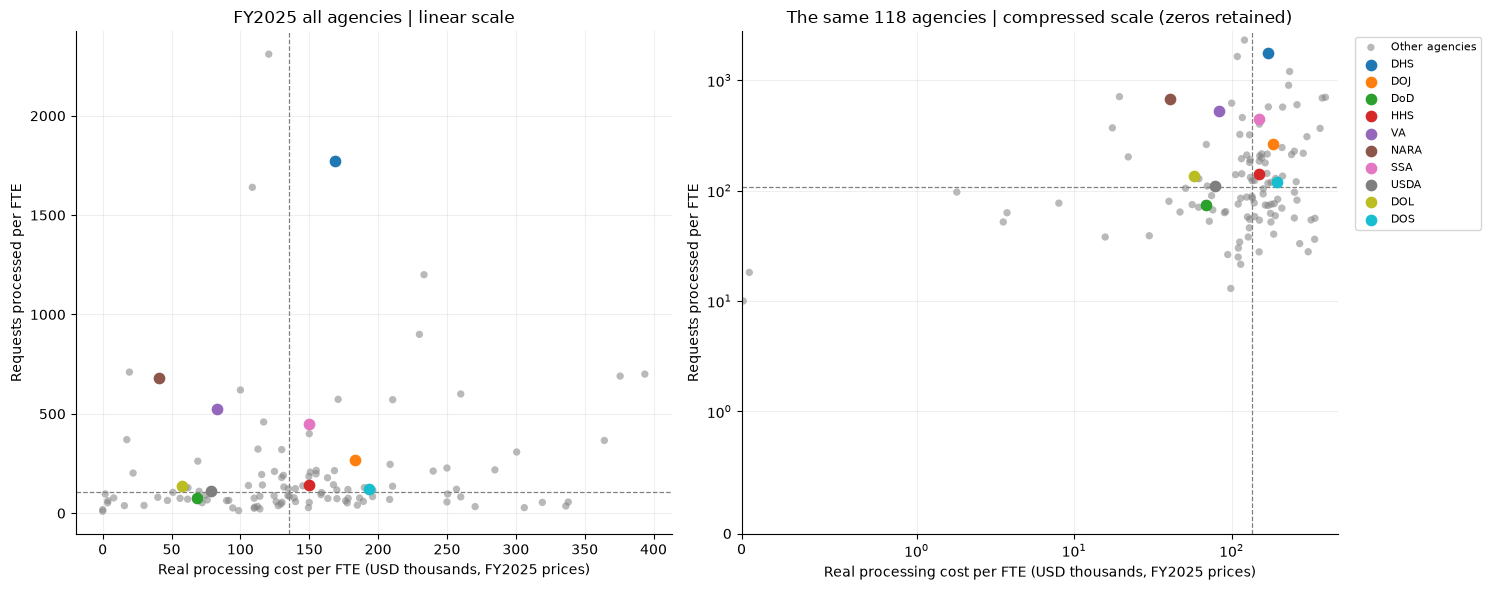

**All-agency results:** FY2025 contains 118 agency-overall records; 118 can be plotted and 0 are excluded because of missing values or an invalid FTE denominator. Cost per FTE and completions per FTE show positive correlation (r=0.118); Spearman rank correlation is 0.190. Of the 59 agencies below the current-year cost median, 34 also fall below the corresponding output median.

This is an all-agency cross-section; its median reference group differs from the top-ten chart. Both ratios share FTE, so common-denominator effects and extreme values may influence correlation. Higher cost cannot be interpreted as causing higher output.

In [6]:
all_year = int(a.year.max())
all_latest = a[a.year.eq(all_year)].copy()
all_latest['cost_per_fte'] = all_latest.real_cost / all_latest.fte.where(all_latest.fte.gt(0))
all_latest['processed_per_fte'] = all_latest.processed / all_latest.fte.where(all_latest.fte.gt(0))
all_plot = all_latest.replace([np.inf, -np.inf], np.nan).dropna(subset=['cost_per_fte', 'processed_per_fte']).copy()
assert not all_plot.agency.duplicated().any()
all_cost_mid = all_plot.cost_per_fte.median()
all_output_mid = all_plot.processed_per_fte.median()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax in axes:
    background = all_plot[~all_plot.agency.isin(TOP)]
    ax.scatter(background.cost_per_fte / 1000, background.processed_per_fte, color='gray', alpha=0.55, s=28, label='Other agencies', edgecolors='none')
    for ag in TOP:
        q = all_plot[all_plot.agency.eq(ag)]
        ax.scatter(q.cost_per_fte / 1000, q.processed_per_fte, color=colors[ag], s=55, label=ag, zorder=3)
    ax.axvline(all_cost_mid / 1000, color='gray', ls='--', lw=0.9)
    ax.axhline(all_output_mid, color='gray', ls='--', lw=0.9)
    ax.set(xlabel='Real processing cost per FTE (USD thousands, FY2025 prices)', ylabel='Requests processed per FTE')
axes[0].set_title(f'FY{all_year} all agencies | linear scale')
axes[1].set_xscale('symlog', linthresh=1)
axes[1].set_yscale('symlog', linthresh=1)
axes[1].set_xlim(0, all_plot.cost_per_fte.max() / 1000 * 1.2)
axes[1].set_ylim(0, all_plot.processed_per_fte.max() * 1.2)
axes[1].set_title(f'The same {len(all_plot)} agencies | compressed scale (zeros retained)')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
finish(fig)
all_n, all_r = paired_corr(all_plot, 'cost_per_fte', 'processed_per_fte')
all_rank_r = all_plot.cost_per_fte.rank().corr(all_plot.processed_per_fte.rank())
all_low = all_plot[all_plot.cost_per_fte.lt(all_cost_mid)]
all_low_both = all_low[all_low.processed_per_fte.lt(all_output_mid)]
display(Markdown(f'**All-agency results:** FY{all_year} contains {len(all_latest)} agency-overall records; {all_n} can be plotted and {len(all_latest) - all_n} are excluded because of missing values or an invalid FTE denominator. Cost per FTE and completions per FTE show {corr_words(all_r)}; Spearman rank correlation is {all_rank_r:.3f}. Of the {len(all_low)} agencies below the current-year cost median, {len(all_low_both)} also fall below the corresponding output median.\n\nThis is an all-agency cross-section; its median reference group differs from the top-ten chart. Both ratios share FTE, so common-denominator effects and extreme values may influence correlation. Higher cost cannot be interpreted as causing higher output.'))

## 3. Does higher cost accompany a larger complex-request share?

The local EDA for types 16, 17, and 18 identifies these counts as completed **perfected requests** by processing track. They are a subset of type 01 completions, so equality is not required.

| Measure | Calculation and interpretation |
|---|---|
| Complex-request share | Type 17 total / (types 16 + 17 + 18 totals); describes the mix of these completed requests |
| Track coverage | Three-track total / type 01 completions; shows coverage of all closures. Below 100% is not automatically an error |
| Real cost per FTE / per completion | Compared with complex share; costs are not allocated to individual tracks and cannot be interpreted as cost per complex request |
| Simple / complex median processing days | Type 14, shown separately. Elapsed time includes queuing and does not directly measure difficulty |

Missing and negative counts are not replaced with zeros. Shares require all three counts and a positive sum. Check each track's 13 time-bin counts against its reported total only when all bins are valid. Retain and flag totals exceeding all completions or inconsistent bin sums; also report correlations excluding flagged records. Original totals are not reconstructed or corrected.

Agencies may classify complexity differently. Compare latest-year agency differences, within-agency level correlations, and correlations in consecutive-year changes. The share proxies the mix of **completed work**, not the complexity of receipts or backlog, and cannot alone explain high costs.

,Check,Agency-years
0,Missing three-track total,0
1,Zero three-track total,0
2,Three-track total exceeds type 01 completions,7
3,At least one track's bin sum differs from its ...,0
4,Complex share available,178


**Track-total discrepancies (excluding records with coverage below 100% only):**

,Agency,Fiscal year,Type 01 completions,Three-track total,simple_count bin sum minus reported total,complex_count bin sum minus reported total,expedited_count bin sum minus reported total
392,DOL,2012,19224,19252,0,0,0
870,HHS,2014,42293,42308,0,0,0
1032,NARA,2010,15573,15769,0,0,0
1034,NARA,2012,13746,13763,0,0,0
1035,NARA,2013,13253,13276,0,0,0
1036,NARA,2014,19476,19577,0,0,0
1905,VA,2008,98455,100749,0,0,0


,Agency,Fiscal year,Complex share (%),Track coverage (%),Real cost per FTE (USD),Real cost per completion (USD),Simple median days,Complex median days,Section data flag
297,DHS,2025,79.43,87.67,168894.11,95.40,16.0,33.0,False
387,DOJ,2025,15.23,80.34,182873.45,686.33,6.0,53.0,False
405,DOL,2025,43.74,87.94,57289.71,423.60,6.0,11.0,False
423,DOS,2025,66.15,79.14,193231.81,1607.83,6.0,125.0,False
459,DoD,2025,45.49,84.16,68307.83,917.72,8.0,27.5,True
881,HHS,2025,75.57,84.60,149680.93,1048.32,3.0,35.5,False
1047,NARA,2025,5.78,97.59,40794.08,60.13,3.0,1384.0,False
1610,SSA,2025,8.00,96.91,149693.77,332.69,6.0,35.0,False
1783,USDA,2025,6.67,97.41,78331.71,705.49,1.0,59.0,False
1922,VA,2025,5.07,96.35,83170.29,158.90,13.5,37.5,False


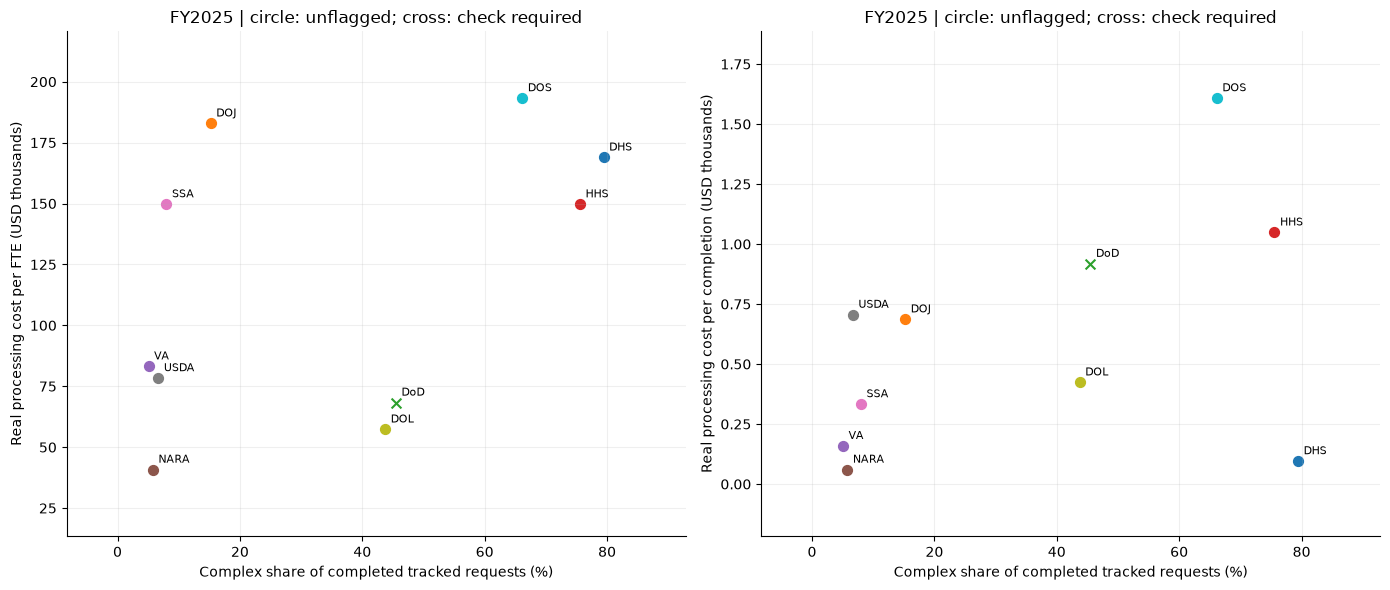

,Agency,Level N,Share vs cost/FTE r,Unit-cost N,Share vs cost/completion r,Change N,Share change vs cost/FTE change r,Unflagged level N,Unflagged level r,Unflagged change N,Unflagged change r
0,DHS,18,0.292,18,-0.450,17,0.323,18,0.292,17,0.323
1,DOJ,18,0.441,18,0.408,17,0.064,18,0.441,17,0.064
2,DoD,18,-0.642,18,0.397,17,0.359,17,-0.638,16,0.308
3,HHS,18,-0.654,18,0.166,17,-0.030,17,-0.637,15,-0.010
4,VA,18,0.262,18,0.022,17,-0.265,17,0.278,16,-0.278
5,NARA,18,-0.181,18,0.168,17,-0.272,14,-0.460,11,-0.081
6,SSA,18,0.287,18,0.722,17,0.352,18,0.287,17,0.352
7,USDA,16,-0.046,16,0.490,15,0.092,16,-0.046,15,0.092
8,DOL,18,0.094,18,0.424,17,-0.171,17,0.092,15,-0.180
9,DOS,18,0.307,18,0.510,17,-0.316,18,0.307,17,-0.316


**Interpretation:** In the latest year, complex share and real cost per FTE show, across 10 valid agencies, positive correlation (r=0.452); complex share and real cost per completion show, across 10 agencies, positive correlation (r=0.446). Within-agency level correlations are positive in 6 agencies (DHS, DOJ, VA, SSA, DOL, DOS) and negative in 4 agencies (DoD, HHS, NARA, USDA).

- **DHS:** Complex share versus cost per FTE: positive correlation (r=0.292); consecutive-year changes: positive correlation (r=0.323).
- **DOJ:** Complex share versus cost per FTE: positive correlation (r=0.441); consecutive-year changes: positive correlation (r=0.064).
- **DoD:** Complex share versus cost per FTE: negative correlation (r=-0.642); consecutive-year changes: positive correlation (r=0.359).
- **HHS:** Complex share versus cost per FTE: negative correlation (r=-0.654); consecutive-year changes: negative correlation (r=-0.030).
- **VA:** Complex share versus cost per FTE: positive correlation (r=0.262); consecutive-year changes: negative correlation (r=-0.265).
- **NARA:** Complex share versus cost per FTE: negative correlation (r=-0.181); consecutive-year changes: negative correlation (r=-0.272).
- **SSA:** Complex share versus cost per FTE: positive correlation (r=0.287); consecutive-year changes: positive correlation (r=0.352).
- **USDA:** Complex share versus cost per FTE: negative correlation (r=-0.046); consecutive-year changes: positive correlation (r=0.092).
- **DOL:** Complex share versus cost per FTE: positive correlation (r=0.094); consecutive-year changes: negative correlation (r=-0.171).
- **DOS:** Complex share versus cost per FTE: positive correlation (r=0.307); consecutive-year changes: negative correlation (r=-0.316).

A positive correlation means higher complex shares tend to accompany higher cost indicators; a negative correlation does not support that same-direction description. Read change correlations, unflagged versions, and coverage together. Cross-agency correlations cannot be generalized to every agency's internal pattern. Pay, contracting, request pages, and other differences are not controlled, and costs are not allocated specifically to complex requests. These associations therefore cannot establish that complexity increases cost. Simple/complex processing times are contextual indicators; longer time does not prove greater difficulty.

In [7]:
mix = co.copy()
track_prefixes = {'simple_count': '16_SimpleRequests__', 'complex_count': '17_ComplexRequests__', 'expedited_count': '18_ExpeditedRequests__'}
track_columns = []
for short, prefix in track_prefixes.items():
    field = prefix + 'TimeIncrementTotalQuantity'
    values = pd.to_numeric(mix[field], errors='coerce')
    mix[short] = values.mask(values.lt(0))
    track_columns.append(short)
    bins = [c for c in mix.columns if c.startswith(prefix + 'TimeIncrementProcessedQuantity[')]
    assert len(bins) == 13
    bin_values = mix[bins].apply(pd.to_numeric, errors='coerce')
    bin_values = bin_values.mask(bin_values.lt(0))
    mix[short + '_bin_gap'] = bin_values.sum(axis=1, min_count=len(bins)) - mix[short]
mix['track_total'] = mix[track_columns].sum(axis=1, min_count=3)
mix['complex_share'] = mix.complex_count / mix.track_total.where(mix.track_total.gt(0))
mix['track_coverage'] = mix.track_total / mix.processed.where(mix.processed.gt(0))
mix['track_flag'] = mix.track_total.gt(mix.processed + 0.5)
for short in track_columns:
    mix['track_flag'] |= mix[short + '_bin_gap'].abs().gt(0.5)
mix['complex_share_pct'] = 100 * mix.complex_share
mix['track_coverage_pct'] = 100 * mix.track_coverage
mix['mix_quality_flag'] = mix.track_flag | mix.fte_flag | mix.cost_flag
mix['mix_pair_flag'] = mix.mix_quality_flag | mix.groupby('agency').mix_quality_flag.shift().eq(True)
mix['change_complex_share'] = mix.complex_share - mix.groupby('agency').complex_share.shift().where(co_consecutive)
display(pd.DataFrame({'Check': ['Missing three-track total', 'Zero three-track total', 'Three-track total exceeds type 01 completions', "At least one track's bin sum differs from its reported total", 'Complex share available'], 'Agency-years': [int(mix.track_total.isna().sum()), int(mix.track_total.eq(0).sum()), int(mix.track_total.gt(mix.processed + 0.5).sum()), int(mix[[s + '_bin_gap' for s in track_columns]].abs().gt(0.5).any(axis=1).sum()), int(mix.complex_share.notna().sum())]}))
display(Markdown('**Track-total discrepancies (excluding records with coverage below 100% only):**'))
table(mix.loc[mix.track_flag, ['agency', 'year', 'processed', 'track_total'] + [s + '_bin_gap' for s in track_columns]], {'agency': 'Agency', 'year': 'Fiscal year', 'processed': 'Type 01 completions', 'track_total': 'Three-track total', **{s + '_bin_gap': s + ' bin sum minus reported total' for s in track_columns}}, 0)
mix_latest = mix[mix.year.eq(mix.year.max())].copy()
table(mix_latest[['agency', 'year', 'complex_share_pct', 'track_coverage_pct', 'cost_per_fte', 'cost_per_completed', 'simple_days', 'complex_days', 'mix_quality_flag']], {'agency': 'Agency', 'year': 'Fiscal year', 'complex_share_pct': 'Complex share (%)', 'track_coverage_pct': 'Track coverage (%)', 'cost_per_fte': 'Real cost per FTE (USD)', 'cost_per_completed': 'Real cost per completion (USD)', 'simple_days': 'Simple median days', 'complex_days': 'Complex median days', 'mix_quality_flag': 'Section data flag'}, 2)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, metric, label in zip(axes, ['cost_per_fte', 'cost_per_completed'], ['Real processing cost per FTE (USD thousands)', 'Real processing cost per completion (USD thousands)']):
    for _, row in mix_latest.dropna(subset=['complex_share_pct', metric]).iterrows():
        ax.scatter(row.complex_share_pct, row[metric] / 1000, color=colors[row.agency], s=50, marker='x' if row.mix_quality_flag else 'o')
        ax.annotate(row.agency, (row.complex_share_pct, row[metric] / 1000), xytext=(4, 5), textcoords='offset points', fontsize=8)
    ax.set(xlabel='Complex share of completed tracked requests (%)', ylabel=label, title=f'FY{int(mix.year.max())} | circle: unflagged; cross: check required')
    ax.margins(0.18)
finish(fig)
mix_rows = []
for ag in TOP:
    q = mix[mix.agency.eq(ag)]
    n, r = paired_corr(q, 'complex_share', 'cost_per_fte')
    nc, rc = paired_corr(q, 'complex_share', 'cost_per_completed')
    nd, rd = paired_corr(q, 'change_complex_share', 'change_cost_per_fte')
    clean = q[~q.mix_quality_flag]
    ns, rs = paired_corr(clean, 'complex_share', 'cost_per_fte')
    clean_delta = q[~q.mix_pair_flag]
    nsd, rsd = paired_corr(clean_delta, 'change_complex_share', 'change_cost_per_fte')
    mix_rows.append([ag, n, r, nc, rc, nd, rd, ns, rs, nsd, rsd])
mix_corr = pd.DataFrame(mix_rows, columns=['Agency', 'Level N', 'Share vs cost/FTE r', 'Unit-cost N', 'Share vs cost/completion r', 'Change N', 'Share change vs cost/FTE change r', 'Unflagged level N', 'Unflagged level r', 'Unflagged change N', 'Unflagged change r'])
table(mix_corr)
mn, mr = paired_corr(mix_latest, 'complex_share', 'cost_per_fte')
un, ur = paired_corr(mix_latest, 'complex_share', 'cost_per_completed')
positives = mix_corr.loc[mix_corr['Share vs cost/FTE r'].gt(0), 'Agency'].tolist()
negatives = mix_corr.loc[mix_corr['Share vs cost/FTE r'].lt(0), 'Agency'].tolist()
mix_notes = []
for _, row in mix_corr.iterrows():
    mix_notes.append(f"- **{row['Agency']}:** Complex share versus cost per FTE: {corr_words(row['Share vs cost/FTE r'])}; consecutive-year changes: {corr_words(row['Share change vs cost/FTE change r'])}.")
display(Markdown(f"**Interpretation:** In the latest year, complex share and real cost per FTE show, across {mn} valid agencies, {corr_words(mr)}; complex share and real cost per completion show, across {un} agencies, {corr_words(ur)}. Within-agency level correlations are positive in {len(positives)} agencies ({', '.join(positives) or 'none'}) and negative in {len(negatives)} agencies ({', '.join(negatives) or 'none'}).\n\n" + '\n'.join(mix_notes) + "\n\nA positive correlation means higher complex shares tend to accompany higher cost indicators; a negative correlation does not support that same-direction description. Read change correlations, unflagged versions, and coverage together. Cross-agency correlations cannot be generalized to every agency's internal pattern. Pay, contracting, request pages, and other differences are not controlled, and costs are not allocated specifically to complex requests. These associations therefore cannot establish that complexity increases cost. Simple/complex processing times are contextual indicators; longer time does not prove greater difficulty."))
assert mix.complex_share.dropna().between(0, 1).all()
assert not mix.duplicated(['agency', 'year']).any()

## 4. What additional context comes from track-specific processing times?

Compare median days for simple and complex requests separately; do not add or average their medians. Elapsed time includes queuing and other factors, so it is not a direct measure of task difficulty.

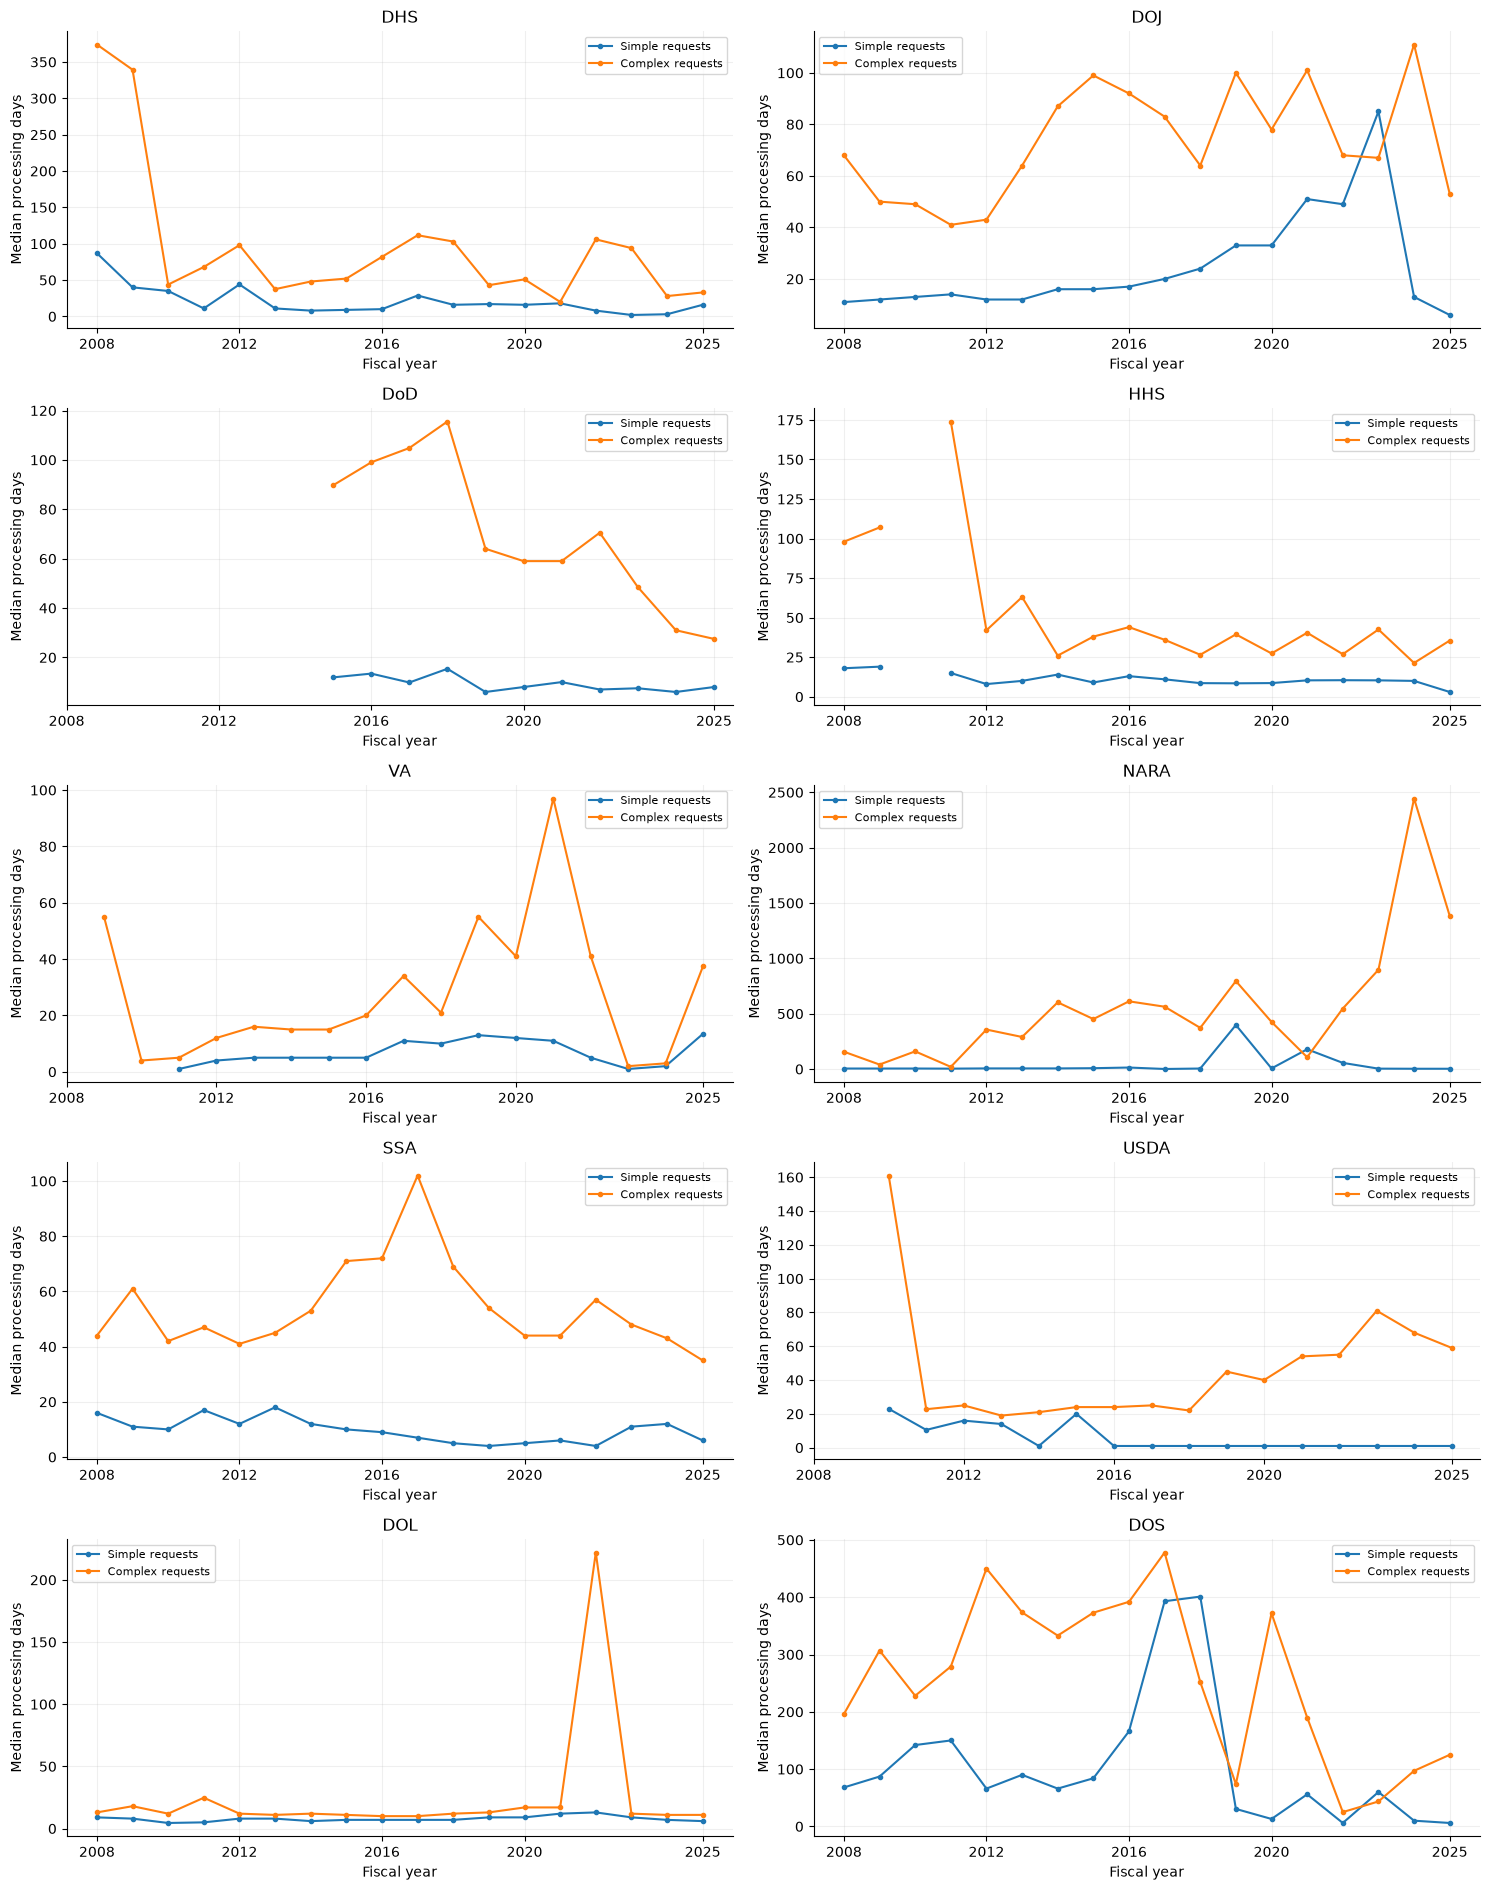

**Latest-year comparison by measure:**

- **Higher personnel productivity：** DHS: 1770.45; opposite end: DoD: 74.43; valid agencies: 10.
- **Lower crude unit cost：** NARA: 60.13; opposite end: DOS: 1607.83; valid agencies: 10.
- **Faster simple processing：** USDA: 1.00; opposite end: DHS: 16.00; valid agencies: 10.
- **Faster complex processing：** DOL: 11.00; opposite end: NARA: 1384.00; valid agencies: 10.

These comparisons assess individual measures, not overall efficiency. Tracks are compared separately; missing times are excluded. Personnel, cost, and output may cover different work, so consult the data flags above.

In [8]:
latest = d[d.year.eq(d.year.max())].copy()
fig, axes = plt.subplots(5, 2, figsize=(15, 19))
for ax, ag in zip(axes.flat, TOP):
    q = d[d.agency.eq(ag)]
    ax.plot(q.year, q.simple_days, label='Simple requests', marker='o', ms=3)
    ax.plot(q.year, q.complex_days, label='Complex requests', marker='o', ms=3)
    style_year(ax, ag, 'Median processing days')
    ax.legend(fontsize=8)
finish(fig)
metric_specs = [('processed_per_fte', 'Higher personnel productivity', False), ('cost_per_completed', 'Lower crude unit cost', True), ('simple_days', 'Faster simple processing', True), ('complex_days', 'Faster complex processing', True)]
comparison = []
for metric, meaning, ascending in metric_specs:
    q = latest.dropna(subset=[metric]).sort_values(metric, ascending=ascending)
    if len(q):
        first, last = (q.iloc[0], q.iloc[-1])
        comparison.append(f'- **{meaning}：** {first.agency}: {first[metric]:.2f}; opposite end: {last.agency}: {last[metric]:.2f}; valid agencies: {len(q)}.')
display(Markdown('**Latest-year comparison by measure:**\n\n' + '\n'.join(comparison) + '\n\nThese comparisons assess individual measures, not overall efficiency. Tracks are compared separately; missing times are excluded. Personnel, cost, and output may cover different work, so consult the data flags above.'))

## 5. Answering the core question

In [9]:
display(Markdown(f"Among the {len(low_cost)} agencies below the latest-year cost-per-FTE median, {len(low_both)} also fall below the output-per-FTE median; the remaining agencies are {', '.join(counter.agency) or 'none'}. Low cost does not necessarily accompany low output.\n\nIn the latest year, complex share and cost per FTE show {corr_words(mr)}; within-agency level correlations are positive in {len(positives)} agencies and negative in {len(negatives)} agencies. Cross-agency relationships cannot replace within-agency evidence.\n\nComplex share describes completed perfected requests only. Without page counts, dedicated labor time, or track-specific costs, these data cannot establish that complexity causes cost differences. Individual cost, output, and time measures can be compared, but do not establish an overall agency efficiency ranking."))

Among the 5 agencies below the latest-year cost-per-FTE median, 3 also fall below the output-per-FTE median; the remaining agencies are NARA, VA. Low cost does not necessarily accompany low output.

In the latest year, complex share and cost per FTE show positive correlation (r=0.452); within-agency level correlations are positive in 6 agencies and negative in 4 agencies. Cross-agency relationships cannot replace within-agency evidence.

Complex share describes completed perfected requests only. Without page counts, dedicated labor time, or track-specific costs, these data cannot establish that complexity causes cost differences. Individual cost, output, and time measures can be compared, but do not establish an overall agency efficiency ranking.

## Sources and reproduction

FOIA data: `component_master_no_03_06_11.csv` in this directory, from branch fa26-Tianqi, commit `c99a9a4af91d558da9a83c3c8e987f79de710f0a`. Price adjustment uses `cpi_u_bls_monthly_2007_2025.csv`. Keep both CSVs beside this notebook, select a Python kernel, and Run All. Dependencies: pandas, NumPy, Matplotlib, and IPython. Execution requires no network access, does not modify source data, and does not read variables or outputs from another notebook.

Independent storylines: [Personnel and costs](FOIA-story-1-personnel-costs.ipynb) · [Staffing and backlog](FOIA-story-2-staffing-backlog.ipynb) · [Cost, output, and task mix](FOIA-story-3-cost-output-complexity.ipynb). The original complete analysis is retained as a working reference.
